# **Homework 06 - Machine Learning - Zoomcamp 2026**

## **Imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

print(f"scikit-learn {sklearn.__version__}, xgboost {xgb.__version__}")

scikit-learn 1.7.2, xgboost 3.2.0


The Random Forest results depend on the Scikit-Learn version. With 1.9.1 the validation RMSE of Question 02 is 1.833, which is not among the options, and Question 03 changes from 100 to 150. With 1.7.2, the version of the course reference replay, the results match the options, so the project pins `scikit-learn==1.7.2` and `xgboost==3.2.0`.

## **Download car fuel efficiency dataset**

In [2]:
DATA_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

df_cars = pd.read_csv(DATA_URL)

df_cars.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


The target for this regression task is the `fuel_efficiency_mpg` column.

## **Preparing the dataset**

Check the missing values:

In [3]:
df_cars.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

As requested, all missing values are filled with zeros:

In [4]:
target = "fuel_efficiency_mpg"

df_cars = df_cars.fillna(0)

df_cars.isnull().sum().sum()

np.int64(0)

## **Split the dataset**

We split the dataset into 60% train, 20% validation and 20% test, with the exact calls of the homework:

In [5]:
# Split the dataset into 80% (train + val) and 20% test
df_full_train, df_test = train_test_split(df_cars, test_size=0.2, random_state=1)

# Split the full train into 60% train and 20% validation (20% / 80% = 25%)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [6]:
# Reset indexes to get sequential ascending order
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [7]:
# Store the target variable of each dataset division, before deleting it
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

`DictVectorizer(sparse=True)` turns each row into a dictionary and one-hot encodes the categorical features, keeping the numerical ones as they are:

In [8]:
dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))

X_train.shape, X_val.shape

((6000, 16), (2000, 16))

In [9]:
dv.feature_names_

['acceleration',
 'drivetrain=All-wheel drive',
 'drivetrain=Front-wheel drive',
 'drivetrain=Rear-wheel drive',
 'engine_displacement',
 'fuel_type=Diesel',
 'fuel_type=Gasoline',
 'fuel_type=Hybrid',
 'horsepower',
 'model_year',
 'num_cylinders',
 'num_doors',
 'origin=Asia',
 'origin=Europe',
 'origin=USA',
 'vehicle_weight']

## **Question 01**

- **Problem statement: Which original feature is used for splitting the data by a decision tree regressor with `max_depth=1`?**

### **Solution**

A tree with `max_depth=1` makes a single split, at the root. `export_text` shows the feature and the threshold of that split:

In [10]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.feature_names_)))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



If the root feature were a one-hot column such as `origin=USA`, its original column would be the part before the `=`:

In [11]:
root_feature = dv.feature_names_[dt.tree_.feature[0]]
root_feature.split("=")[0]

'model_year'

> **Answer: The feature used for splitting the data is `'model_year'`.**

## **Question 02**

- **Problem statement: What's the RMSE on the validation data of a random forest regressor with `n_estimators=10`?**

### **Solution**

In [12]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)

rmse = root_mean_squared_error(y_val, y_pred)
round(rmse, 3)

1.837

> **Answer: The RMSE on the validation data is 1.837.**

## **Question 03**

- **Problem statement: Which value of `n_estimators` among `[10, 50, 100, 150]` gives the lowest validation RMSE (considering 3 decimal places)?**

### **Solution**

In [13]:
scores = []
for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    scores.append((n, round(root_mean_squared_error(y_val, y_pred), 3)))

df_n_estimators = pd.DataFrame(scores, columns=["n_estimators", "rmse"])
df_n_estimators

,n_estimators,rmse
0,10,1.837
1,50,1.772
2,100,1.768
3,150,1.769


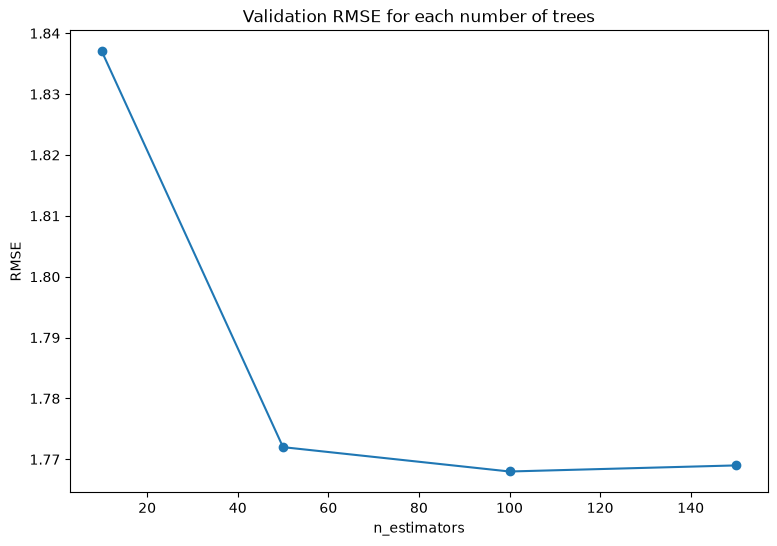

In [14]:
plt.figure(figsize=(9, 6))
plt.plot(df_n_estimators["n_estimators"], df_n_estimators["rmse"], marker="o")
plt.xlabel("n_estimators")
plt.ylabel("RMSE")
plt.title("Validation RMSE for each number of trees")
plt.show()

The RMSE drops quickly up to 50 trees and almost stops improving after that: 100 and 150 differ only in the third decimal place.

> **Answer: `n_estimators = 100` gives the lowest validation RMSE (1.768).**

## **Question 04**

- **Problem statement: What's the best `max_depth` among `[10, 15, 20, 25]`, using the mean RMSE over `n_estimators` in `[10, 50, 100, 150]`?**

### **Solution**

In [15]:
scores = []
for depth in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        scores.append((depth, n, root_mean_squared_error(y_val, y_pred)))

df_depth = pd.DataFrame(scores, columns=["max_depth", "n_estimators", "rmse"])
df_depth.pivot(index="n_estimators", columns="max_depth", values="rmse").round(3)

max_depth,10,15,20,25
n_estimators,,,,
10,1.784,1.830,1.841,1.837
50,1.749,1.771,1.773,1.772
100,1.745,1.768,1.769,1.768
150,1.745,1.767,1.770,1.768


In [16]:
df_depth.groupby("max_depth")["rmse"].mean().round(3).to_frame(name="mean_rmse")

,mean_rmse
max_depth,
10,1.755
15,1.784
20,1.788
25,1.786


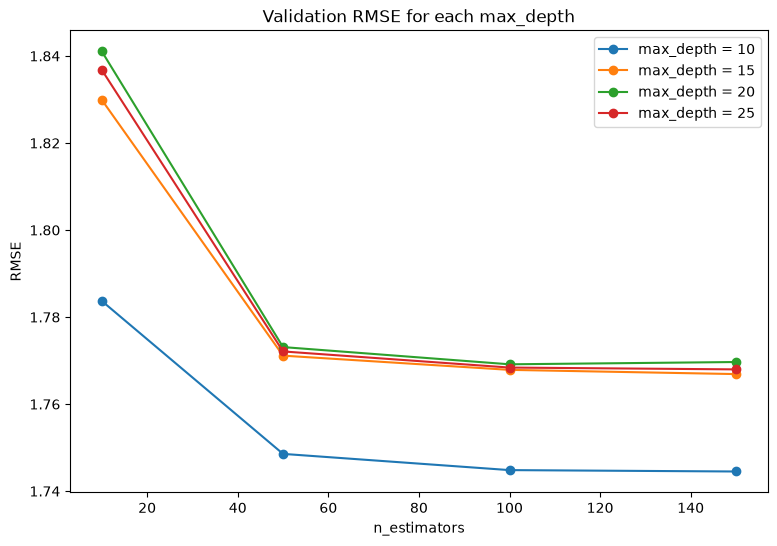

In [17]:
plt.figure(figsize=(9, 6))
for depth, group in df_depth.groupby("max_depth"):
    plt.plot(group["n_estimators"], group["rmse"], marker="o", label=f"max_depth = {depth}")
plt.xlabel("n_estimators")
plt.ylabel("RMSE")
plt.title("Validation RMSE for each max_depth")
plt.legend()
plt.show()

> **Answer: The best `max_depth` is 10 (mean RMSE of 1.755).**

## **Question 05**

- **Problem statement: Which is the most important feature among `vehicle_weight`, `horsepower`, `acceleration` and `engine_displacement`?**

### **Solution**

`feature_importances_` is the total impurity reduction brought by each feature, averaged over the trees and normalized to sum to 1:

In [18]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

df_importance = pd.DataFrame({"feature": dv.feature_names_, "importance": rf.feature_importances_})
df_importance.sort_values(by="importance", ascending=False).round(3)

,feature,importance
9,model_year,0.296
15,vehicle_weight,0.204
6,fuel_type=Gasoline,0.161
8,horsepower,0.078
4,engine_displacement,0.061
0,acceleration,0.055
14,origin=USA,0.042
2,drivetrain=Front-wheel drive,0.020
11,num_doors,0.019
5,fuel_type=Diesel,0.017


In [19]:
candidates = ["vehicle_weight", "horsepower", "acceleration", "engine_displacement"]

df_importance[df_importance["feature"].isin(candidates)].sort_values(by="importance", ascending=False).round(3)

,feature,importance
15,vehicle_weight,0.204
8,horsepower,0.078
4,engine_displacement,0.061
0,acceleration,0.055


`model_year` is the most important feature overall, as in Question 01, but it is not among the options.

> **Answer: `vehicle_weight` is the most important feature among the four (importance of 0.204).**

## **Question 06**

- **Problem statement: Which `eta` leads to the best RMSE on the validation dataset: 0.3, 0.1, or both give equal value?**

### **Solution**

XGBoost uses its own data structure, the `DMatrix`. The watchlist makes it compute the RMSE on train and validation after every round, which `evals_result` stores:

In [20]:
features = list(dv.feature_names_)

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

watchlist = [(dtrain, "train"), (dval, "val")]

In [21]:
def train_xgb(eta: float) -> tuple[xgb.Booster, dict]:
    """Train an XGBoost regressor for 100 rounds with the homework parameters.

    Args:
        eta: Learning rate.

    Returns:
        The trained model and the RMSE of each round on train and validation.
    """
    xgb_params = {
        "eta": eta,
        "max_depth": 6,
        "min_child_weight": 1,

        "objective": "reg:squarederror",
        "nthread": 8,

        "seed": 1,
        "verbosity": 1,
    }

    evals_result = {}
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=100,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )
    return model, evals_result

In [22]:
results = {}
for eta in [0.3, 0.1]:
    model, evals_result = train_xgb(eta)
    rmse = root_mean_squared_error(y_val, model.predict(dval))
    results[eta] = evals_result["val"]["rmse"]
    print(f"eta = {eta}: validation RMSE = {rmse:.3f}")

eta = 0.3: validation RMSE = 1.826
eta = 0.1: validation RMSE = 1.725


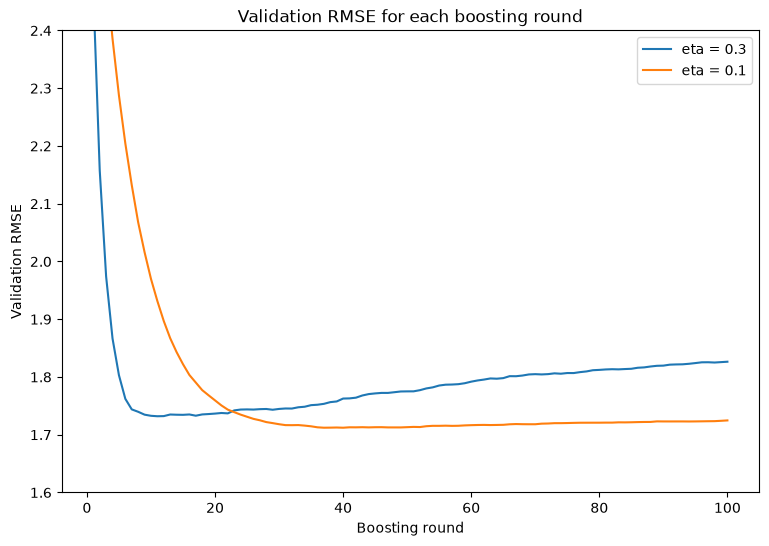

In [23]:
plt.figure(figsize=(9, 6))
for eta, val_rmse in results.items():
    plt.plot(range(1, len(val_rmse) + 1), val_rmse, label=f"eta = {eta}")
plt.xlabel("Boosting round")
plt.ylabel("Validation RMSE")
plt.ylim(1.6, 2.4)
plt.title("Validation RMSE for each boosting round")
plt.legend()
plt.show()

With `eta = 0.3` the validation RMSE reaches its minimum (1.732) at round 11 and then increases to 1.826, because the model starts to overfit. With `eta = 0.1` it decreases more slowly, reaches its minimum (1.712) at round 40 and increases only slightly after that, ending at 1.725.

> **Answer: `eta = 0.1` leads to the best RMSE on the validation dataset (1.725, against 1.826 with `eta = 0.3`).**